In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi




In [3]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root =  str(PREPARES / "heterogeneity") + "/"
mouse='cm125'

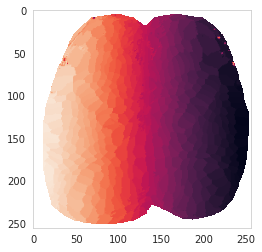

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [5]:

corr_maps = np.zeros((500,500))
with h5py.File(data_root+'500-seed/'+mouse+'_500_corr_maps_dict.h5', 'r') as hf:
    # print(hf.keys())
    for i_key, key in enumerate(list(hf.keys())):
        ind = int(key.split('_')[-1])
        corr_maps[ind,:] = hf[key]
    # for i_key,key in enumerate(all_corr_maps_dict_backup):
    #     hf.create_dataset(key, data=all_corr_maps_dict_backup[key])
    

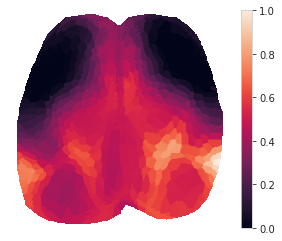

In [6]:
show_map(corr_maps[1,:],caxis=[0,1],IDX_sorted=IDX_sorted)

In [7]:
with h5py.File('masked_S1_strip.mat','r') as f: 
    S1_strip_mask = np.array(f['mask']).T

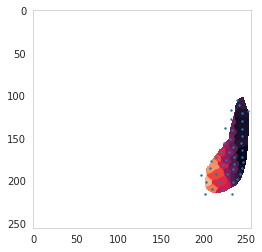

In [8]:
masked_IDX_sorted = np.multiply(IDX_sorted,S1_strip_mask)
plt.imshow(masked_IDX_sorted)

masked_IDX_sorted_ind = np.unique(masked_IDX_sorted)[:-1].astype('int')-1
masked_node_coords = node_coords[masked_IDX_sorted_ind,:]

plt.scatter(masked_node_coords[:,1],masked_node_coords[:,0],s=2)

In [9]:
# Combine the coordinates with the labels for sorting
combined = np.hstack([masked_node_coords, masked_IDX_sorted_ind.reshape(-1, 1)])

# Sort first by X (left to right), then by Y (top to bottom)
sorted_combined = combined[np.lexsort((combined[:, 1], combined[:, 0]))]

# Extract sorted coordinates and labels
sorted_coordinates = sorted_combined[:, :2]
sorted_labels = sorted_combined[:, 2].astype('int')


In [10]:
sorted_labels = sorted_labels[1:-2]
sorted_coordinates = sorted_coordinates[1:-2]

In [11]:
colors_viridis = plt.cm.viridis(np.linspace(0,1,len(sorted_labels)+4))
colors_viridis = colors_viridis[4:,:]


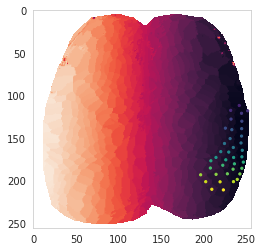

In [12]:
plt.imshow(IDX_sorted)
plt.scatter(sorted_coordinates[:,1],sorted_coordinates[:,0],s=5,color=colors_viridis[:])



In [13]:
corr_maps = np.zeros((256,256,500))
with h5py.File(data_root+'all-seed/'+mouse+'_all_corr_maps_dict.h5', 'r') as hf:
    # print(hf.keys())
    for i_key, key in enumerate(list(hf.keys())):
        ind = int(key.split('-')[-1])
        corr_maps[:,:,ind] = np.arctanh(hf[key])

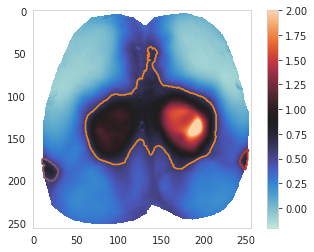

In [14]:
corr_map_here = corr_maps[:,:,100]
plt.imshow(corr_map_here,vmin=-0.2,vmax=2,cmap='icefire')
plt.colorbar()

from skimage import measure
filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_map_here>0.6)
contours = measure.find_contours(filled_bw, 0.1)

shape_of_contours = np.array([len(contour) for contour in contours])
keep_boolean = np.where(shape_of_contours>30)[0]
contours_copy = contours
contours = [contours_copy[i_ind] for i_ind in keep_boolean]

plt.imshow(corr_map_here,vmin=-0.2,vmax=2,cmap='icefire')


for i_c,contour in enumerate(contours):
    plt.plot(contour[:,1],contour[:,0])
    plt.plot(contour[:,1],contour[:,0])

In [9]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


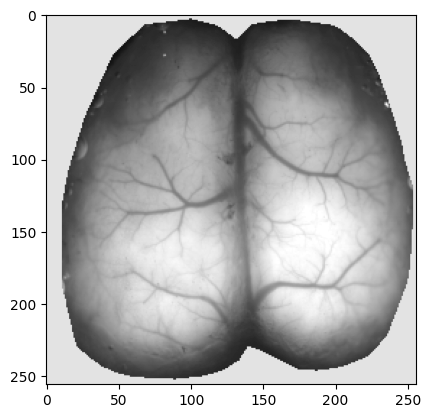

In [10]:
masked_brain_here = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain_here,nan=4000)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)

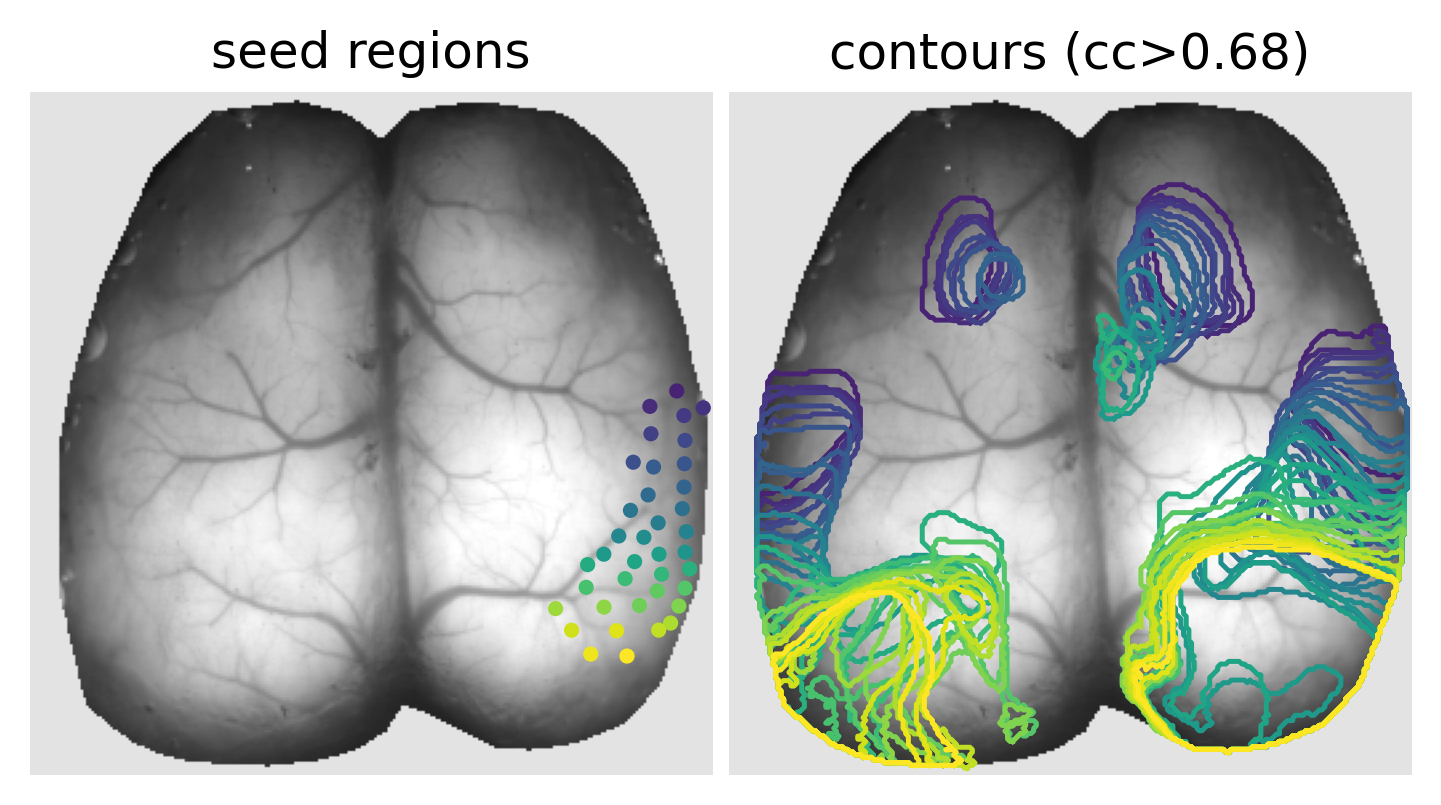

In [17]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])
ax0.axis('off')

x_start = x_stop
x_stop = x_start+x_width
ax1 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])
ax1.axis('off')

ax0.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)
ax0.scatter(sorted_coordinates[:,1],sorted_coordinates[:,0],s=7,color=colors_viridis[:])

ax1.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)

for i_color,i in enumerate(range(len(sorted_labels))):

    corr_map_here = corr_maps[:,:,sorted_labels[i]]
    
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_map_here>0.68)
    contours = measure.find_contours(filled_bw, 0.1)
    
    shape_of_contours = np.array([len(contour) for contour in contours])
    keep_boolean = np.where(shape_of_contours>30)[0]
    contours_copy = contours
    contours = [contours_copy[i_ind] for i_ind in keep_boolean]
        
    for i_c,contour in enumerate(contours):
        ax1.plot(contour[:,1],contour[:,0],alpha=1,linewidth=1.2,color=colors_viridis[i_color])

ax0.set_title('seed regions')
ax1.set_title('contours (F(corr)>0.68)')

plt.savefig('figS4-continuous-M2-S1-v1.svg',format='svg',dpi=300)

In [15]:
# 1) Load mask_midline
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T


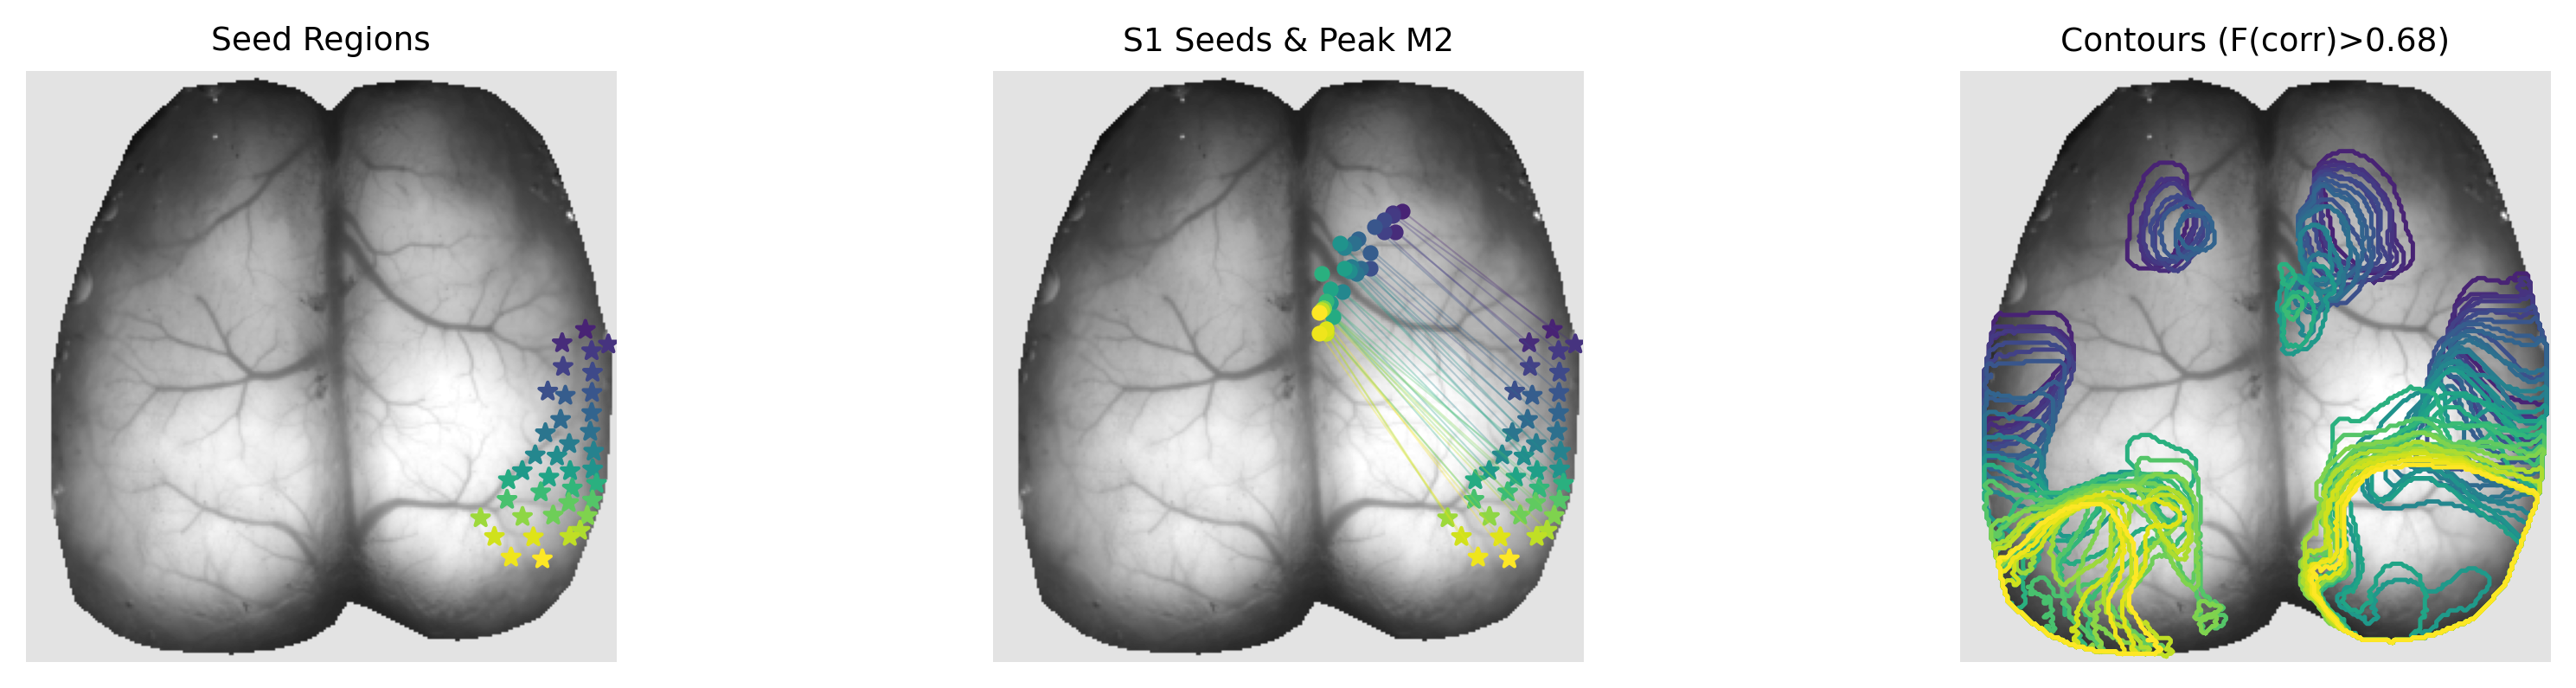

In [35]:
import numpy as np
import scipy.ndimage
from matplotlib.gridspec import GridSpec
from skimage import measure
import matplotlib.pyplot as plt
import h5py


plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

gs = GridSpec(100, 100)
# Increased figsize width to accommodate 3 subplots comfortably
fig = plt.figure(figsize=(40, 30), dpi=300) 

y_offset = 20
x_offset = 10
x_width = 10
x_gap = 2

# ---- Setup Subplots ----
# ax0: Seed regions
x_start = x_offset
x_stop = x_start + x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop])
ax0.axis('off')

# ax_middle: S1 Seeds & M2 Peaks (NEW)
x_start = x_stop + x_gap
x_stop = x_start + x_width
ax_middle = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop])
ax_middle.axis('off')

# ax1: Contours
x_start = x_stop + x_gap
x_stop = x_start + x_width
ax1 = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop])
ax1.axis('off')

# Plot anatomical backgrounds
for ax in [ax0, ax_middle, ax1]:
    ax.imshow(masked_brain, cmap='gray', vmin=0, vmax=4500)

# 2) Plot S1 Seeds with '*' marker
# Increased 's' slightly because star markers visually render smaller than round dots
ax0.scatter(sorted_coordinates[:, 1], sorted_coordinates[:, 0], s=25, marker='*', color=colors_viridis[:])
ax_middle.scatter(sorted_coordinates[:, 1], sorted_coordinates[:, 0], s=25, marker='*', color=colors_viridis[:])

# ---- Process Each Region ----
for i_color, i in enumerate(range(len(sorted_labels))):
    
    # Apply midline mask to the correlation map
    corr_map_here = corr_maps[:, :, sorted_labels[i]]
    corr_map_masked = np.multiply(corr_map_here, mask_midline)
    
    # 3) ---- Find Peak in M2 (Anterior & Ipsilateral) ----
    search_map = corr_map_masked.copy()
    
    # --- THE FIX ---
    # Convert any NaNs in the background to -999 so argmax ignores them
    search_map[np.isnan(search_map)] = -999
    # ---------------
    
    # Rule A: Must be Anterior (M2 territory)
    # Mask out the posterior brain (assuming Bregma/M1 border is ~ y=128)
    search_map[128:, :] = -999 
    search_map[:, 210:] = -999 
    
    # Rule B: Must be Ipsilateral
    seed_x = sorted_coordinates[i, 1]
    if seed_x > 128:
        # Seed is on the Right Hemisphere -> Mask out Left Hemisphere
        search_map[:, :128] = -999 
    else:
        # Seed is on the Left Hemisphere -> Mask out Right Hemisphere
        search_map[:, 128:] = -999 

    # Extract the highest correlation pixel in this isolated M2 zone
    peak_idx = np.argmax(search_map)
    peak_y, peak_x = np.unravel_index(peak_idx, search_map.shape)
    
    # Plot M2 Peak as a circle ('o') to differentiate from S1 stars
    ax_middle.scatter(peak_x, peak_y, s=15, marker='o', color=colors_viridis[i_color], linewidth=0.5, zorder=3)
    
    # Optional visual aid: draw a very faint line connecting the S1 seed to its M2 peak
    ax_middle.plot([seed_x, peak_x], [sorted_coordinates[i, 0], peak_y], color=colors_viridis[i_color], alpha=0.3, linewidth=0.5, zorder=1)
    # -----------------------------------------------------
    # -----------------------------------------------------

    # ---- Contours Subplot ----
    # Using the midline-masked map for cleaner contours
    filled_bw = scipy.ndimage.binary_fill_holes(corr_map_masked > 0.68)
    contours = measure.find_contours(filled_bw, 0.1)
    
    shape_of_contours = np.array([len(contour) for contour in contours])
    keep_boolean = np.where(shape_of_contours > 30)[0]
    contours_copy = contours
    contours = [contours_copy[i_ind] for i_ind in keep_boolean]
        
    for i_c, contour in enumerate(contours):
        ax1.plot(contour[:, 1], contour[:, 0], alpha=1, linewidth=1.2, color=colors_viridis[i_color])

# Titles
ax0.set_title('Seed Regions', fontsize=9)
ax_middle.set_title('S1 Seeds & Peak M2', fontsize=9)
ax1.set_title('Contours (F(corr)>0.68)', fontsize=9)

plt.savefig('figS4-continuous-M2-S1.svg', format='svg', dpi=300)
plt.show()

# spine strip

ROI pixels: 1030
Number of spine seeds: 20


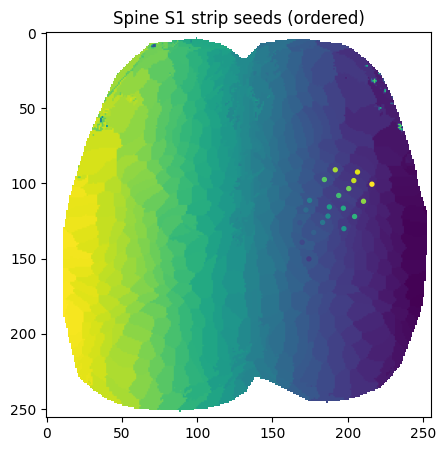

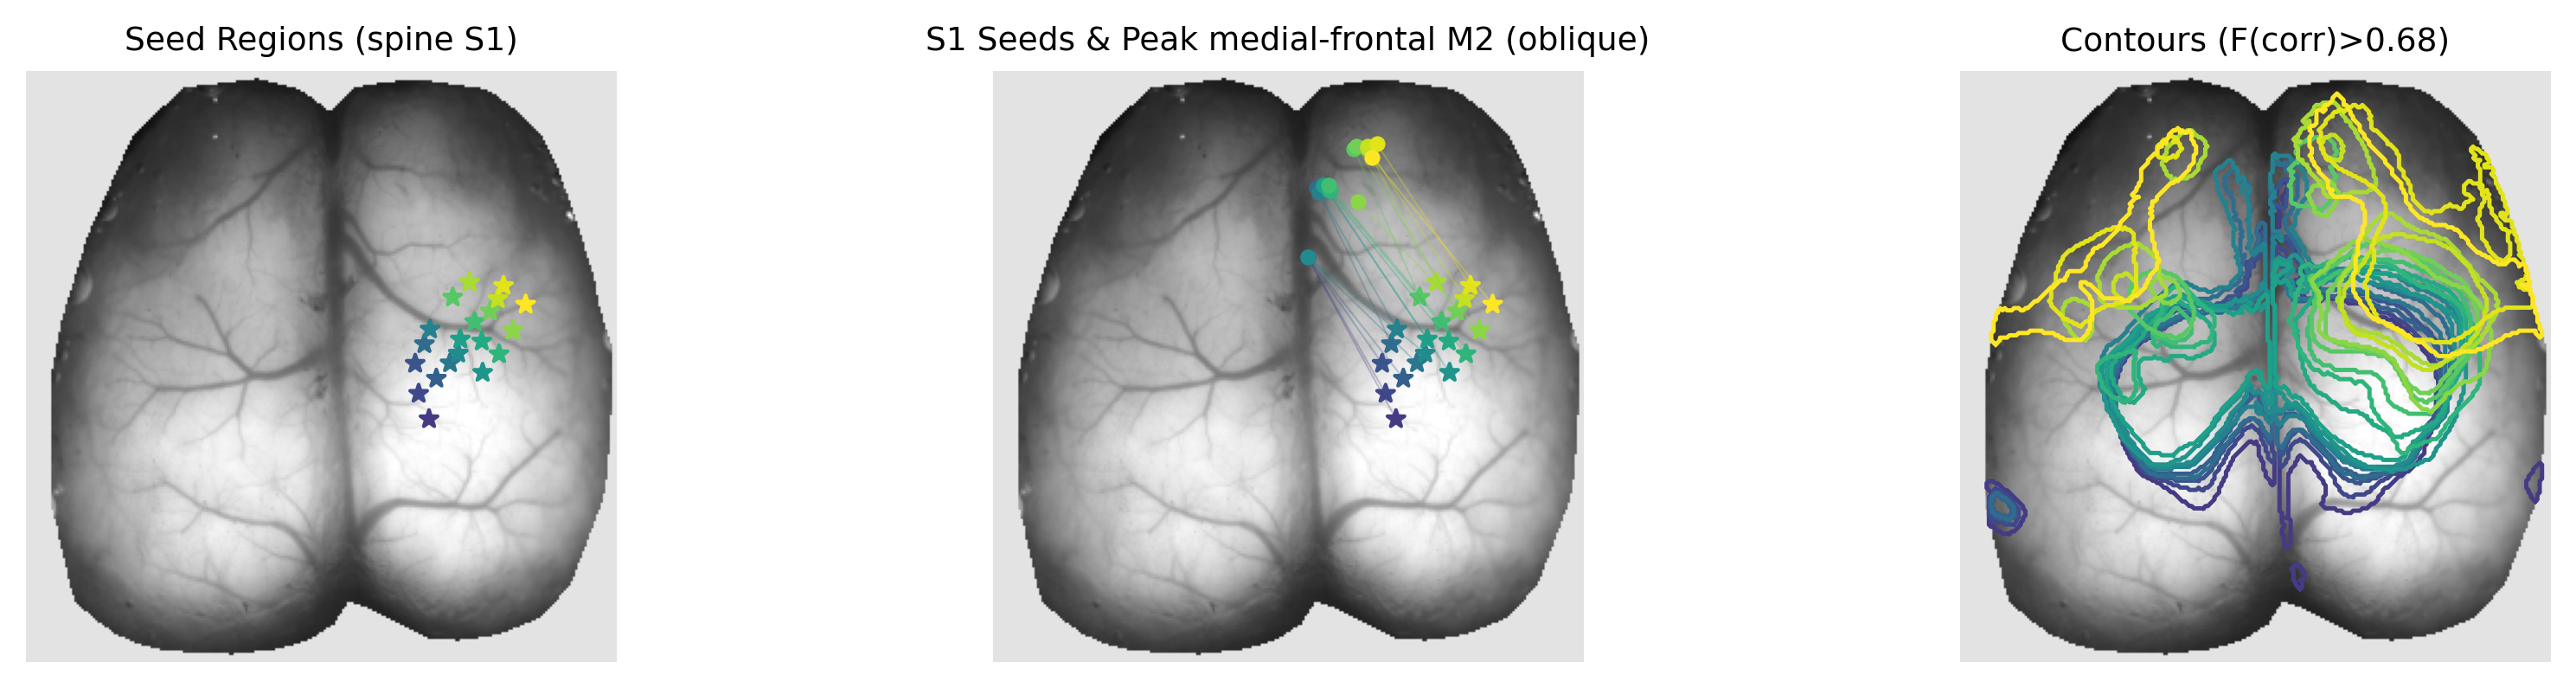

In [71]:
# ============================================================
# SPINE S1 STRIP — single-cell version, no .mat file needed
# Paste a new corners_xy from the drawer widget and rerun.
# ============================================================
from matplotlib.path import Path as MplPath
from matplotlib.patches import Rectangle  # harmless re-import

# --- 1) Polygon vertices from the drawer widget ---------------
corners_xy = np.array([
    [208, 93],
    [214, 102],
    [212, 112],
    [201, 120],
    [193, 126],
    [181, 130],
    [171, 146],
    [172, 134],
    [174, 120],
    [180, 114],
    [186, 105],
    [187, 94],
    [197, 91],
])

# --- 2) Rasterize polygon into a 256x256 mask (1 inside, NaN outside) ---
H = W = 256
_yy, _xx = np.mgrid[0:H, 0:W]
_inside = MplPath(corners_xy).contains_points(
    np.column_stack([_xx.ravel(), _yy.ravel()])
).reshape(H, W)
S1_spine_mask = np.where(_inside, 1.0, np.nan)

print(f"ROI pixels: {int(np.nansum(S1_spine_mask))}")

# --- 3) Find parcels whose centroids fall inside the ROI --------
masked_IDX_sorted_spine = np.multiply(IDX_sorted, S1_spine_mask)
masked_IDX_sorted_spine_ind = np.unique(masked_IDX_sorted_spine)[:-1].astype('int') - 1
masked_node_coords_spine = node_coords[masked_IDX_sorted_spine_ind, :]
print(f"Number of spine seeds: {len(masked_IDX_sorted_spine_ind)}")

# --- 4) Auto-derive strip long axis from the polygon itself -----
#        (uses PCA on the inside-pixel coords; always matches the current shape)
_pts_yx = np.argwhere(_inside)            # (N, 2) as (y, x)
_pts_yx = _pts_yx - _pts_yx.mean(axis=0)
_cov = np.cov(_pts_yx.T)
_evals, _evecs = np.linalg.eigh(_cov)
_long_yx = _evecs[:, -1]                  # principal axis in (dy, dx)
strip_axis_xy = np.array([_long_yx[1], _long_yx[0]], dtype=float)
strip_axis_xy /= np.linalg.norm(strip_axis_xy)
if strip_axis_xy[1] > 0:                  # orient so "along" grows toward anterior
    strip_axis_xy = -strip_axis_xy

# --- 5) Sort seeds along the strip axis -------------------------
coords_xy_spine = np.column_stack([masked_node_coords_spine[:, 1],
                                   masked_node_coords_spine[:, 0]])
order = np.argsort(coords_xy_spine @ strip_axis_xy)
sorted_coordinates_spine = masked_node_coords_spine[order]
sorted_labels_spine     = masked_IDX_sorted_spine_ind[order]

colors_viridis_spine = plt.cm.viridis(np.linspace(0, 1, len(sorted_labels_spine) + 4))[4:, :]

# Quick sanity check — comment out once happy with ordering
plt.figure(figsize=(5, 5))
plt.imshow(IDX_sorted)
plt.scatter(sorted_coordinates_spine[:, 1], sorted_coordinates_spine[:, 0],
            s=8, color=colors_viridis_spine)
plt.title('Spine S1 strip seeds (ordered)')
plt.show()

# --- 6) Oblique medial-frontal M2 search box --------------------
MFC_AXIS_ANT  = np.array([190.0,  0.0])   # anterior-lateral tip (x, y)
MFC_AXIS_POST = np.array([120.0, 63.0])   # posterior-medial tip
MFC_HALF_W    = 24.0

_axis_vec  = MFC_AXIS_POST - MFC_AXIS_ANT
_axis_len  = np.linalg.norm(_axis_vec)
_axis_unit = _axis_vec / _axis_len
_perp_unit = np.array([-_axis_unit[1], _axis_unit[0]])

yy_grid, xx_grid = np.mgrid[0:256, 0:256]
_dx = xx_grid - MFC_AXIS_ANT[0]
_dy = yy_grid - MFC_AXIS_ANT[1]
_along  = _dx * _axis_unit[0] + _dy * _axis_unit[1]
_across = _dx * _perp_unit[0] + _dy * _perp_unit[1]
in_obliq = (_along >= 0) & (_along <= _axis_len) & (np.abs(_across) <= MFC_HALF_W)

_box_corners_box = np.array([[0, -MFC_HALF_W],
                             [_axis_len, -MFC_HALF_W],
                             [_axis_len,  MFC_HALF_W],
                             [0,  MFC_HALF_W],
                             [0, -MFC_HALF_W]])
_box_corners_world = MFC_AXIS_ANT + _box_corners_box @ np.array([_axis_unit, _perp_unit]).T.T

# --- 7) Figure --------------------------------------------------
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
gs = GridSpec(100, 100)
fig = plt.figure(figsize=(40, 30), dpi=300)
y_offset, x_offset, x_width, x_gap = 20, 10, 10, 2

x_start = x_offset;        x_stop = x_start + x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop]); ax0.axis('off')
x_start = x_stop + x_gap;  x_stop = x_start + x_width
ax_middle = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop]); ax_middle.axis('off')
x_start = x_stop + x_gap;  x_stop = x_start + x_width
ax1 = fig.add_subplot(gs[y_offset:y_offset+10, x_start:x_stop]); ax1.axis('off')

for ax in [ax0, ax_middle, ax1]:
    ax.imshow(masked_brain, cmap='gray', vmin=0, vmax=4500)

ax0.scatter(sorted_coordinates_spine[:, 1], sorted_coordinates_spine[:, 0],
            s=25, marker='*', color=colors_viridis_spine)
ax_middle.scatter(sorted_coordinates_spine[:, 1], sorted_coordinates_spine[:, 0],
                  s=25, marker='*', color=colors_viridis_spine)
# ax_middle.plot(_box_corners_world[:, 0], _box_corners_world[:, 1],
#                color='white', linestyle='--', linewidth=0.8, alpha=0.7, zorder=2)

for i_color, i in enumerate(range(len(sorted_labels_spine))):
    corr_map_here   = corr_maps[:, :, sorted_labels_spine[i]]
    corr_map_masked = np.multiply(corr_map_here, mask_midline)

    search_map = corr_map_masked.copy()
    search_map[np.isnan(search_map)] = -999
    search_map[~in_obliq] = -999

    peak_idx = np.argmax(search_map)
    peak_y, peak_x = np.unravel_index(peak_idx, search_map.shape)

    ax_middle.scatter(peak_x, peak_y, s=15, marker='o',
                      color=colors_viridis_spine[i_color], linewidth=0.5, zorder=3)
    ax_middle.plot([sorted_coordinates_spine[i, 1], peak_x],
                   [sorted_coordinates_spine[i, 0], peak_y],
                   color=colors_viridis_spine[i_color],
                   alpha=0.3, linewidth=0.5, zorder=1)

    filled_bw = scipy.ndimage.binary_fill_holes(corr_map_masked > 0.68)
    contours  = measure.find_contours(filled_bw, 0.1)
    contours = [c for c in contours if len(c) > 30]
    for ii,contour in enumerate(contours):
        ax1.plot(contour[:, 1], contour[:, 0],
                 alpha=1, linewidth=1.2, color=colors_viridis_spine[i_color])
    # for ii, contour in enumerate(contours):
    #     ax1.plot(contour[:, 1], contour[:, 0],
    #              alpha=1, linewidth=1.2, color=colors_viridis_spine[i_color],
    #              zorder=len(sorted_labels_spine) - i_color)
        
ax0.set_title('Seed Regions (spine S1)', fontsize=9)
ax_middle.set_title('S1 Seeds & Peak medial-frontal M2 (oblique)', fontsize=9)
ax1.set_title('Contours (F(corr)>0.68)', fontsize=9)

# plt.savefig('figS4-continuous-M2-S1_spine.svg', format='svg', dpi=300)
plt.show()

In [25]:
# save_pickle(IDX_sorted,'IDX_sorted')

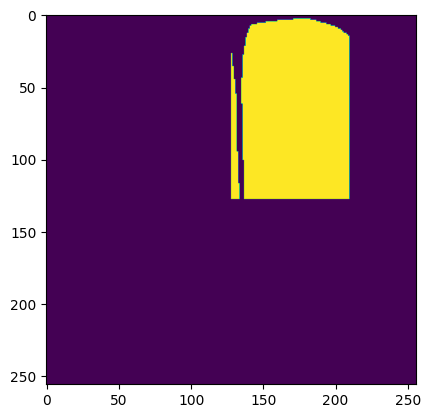

In [31]:
plt.imshow(search_map)


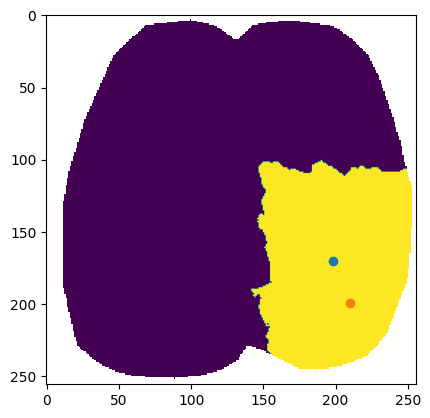

In [57]:
safari_ind = np.logical_and(node_coords[:,0]>105,node_coords[:,1]>150)
safari_map = show_map(safari_ind,[0,1],if_return_map=True,IDX_sorted=IDX_sorted)
props = regionprops(safari_map.astype(int))
cent = props[0].centroid
plt.imshow(safari_map)
plt.scatter(cent[1],cent[0])
plt.scatter(210,199)

In [72]:
START_SEED = 73

In [58]:
import math
def clockwiseangle_and_distance(point):
    # Vector between point and the origin: v = p - o
    vector = [point[0]-origin[0], point[1]-origin[1]]
    # Length of vector: ||v||
    lenvector = math.hypot(vector[0], vector[1])
    # If length is zero there is no angle
    if lenvector == 0:
        return -math.pi, 0
    # Normalize vector: v/||v||
    normalized = [vector[0]/lenvector, vector[1]/lenvector]
    dotprod  = normalized[0]*refvec[0] + normalized[1]*refvec[1]     # x1*x2 + y1*y2
    diffprod = refvec[1]*normalized[0] - refvec[0]*normalized[1]     # x1*y2 - y1*x2
    angle = math.atan2(diffprod, dotprod)
    # Negative angles represent counter-clockwise angles so we need to subtract them 
    # from 2*pi (360 degrees)
    if angle < 0:
        return 2*math.pi+angle, lenvector
    # I return first the angle because that's the primary sorting criterium
    # but if two vectors have the same angle then the shorter distance should come first.
    return angle, lenvector

origin=np.array([210,199]);

refvec = [0, 1];
index_list = np.where(safari_ind==True)[0]+1
safari_coord=node_coords[safari_ind==True,:]
sorted_pts = sorted(safari_coord, key=clockwiseangle_and_distance)
IDX_safari = np.where(safari_ind==True)[0]

In [59]:
sorted_pts_array = np.mean(np.asarray(sorted_pts, dtype=np.float32),axis=1)
safari_coord_array=np.mean(np.asarray(safari_coord, dtype=np.float32),axis=1)
index_sorted = np.zeros(len(sorted_pts_array))
for i_pt,pt in enumerate(sorted_pts_array):
    index_sorted[i_pt] = np.where(safari_coord_array==pt)[0]
        
index_sorted=index_sorted.astype('int')

In [60]:
IDX_safari_sorted = IDX_safari[index_sorted]

In [73]:
n=len(range(START_SEED,len(IDX_safari_sorted)))
colors_jet = plt.cm.jet(np.linspace(0,1,n))

In [43]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


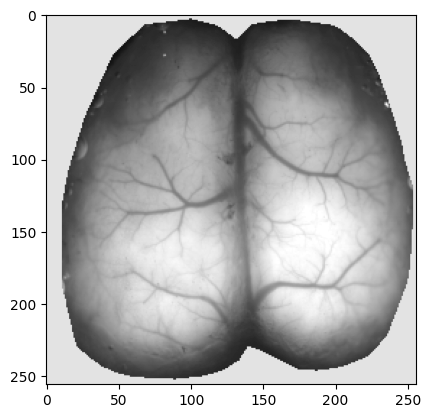

In [75]:
masked_brain_here = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain_here,nan=4000)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)

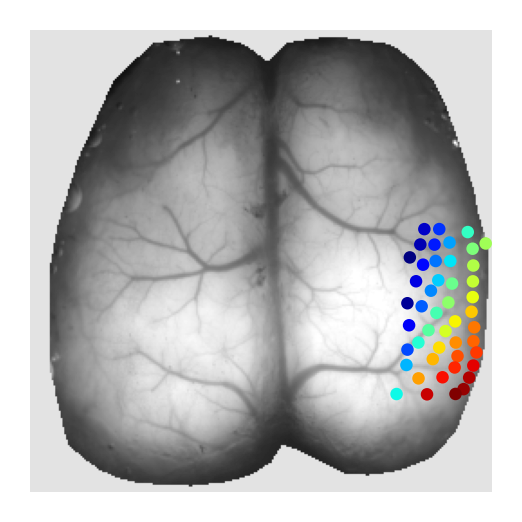

In [77]:
fig = plt.figure(figsize=(2,2),dpi=300)
plt.style.use('default')
ax2 = fig.add_subplot(111, aspect='equal')
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)
plt.axis('off')
# for i in range(len(IDX_safari_sorted)):
plt.scatter(node_coords[IDX_safari_sorted[START_SEED:],1],node_coords[IDX_safari_sorted[START_SEED:],0],s=4,color=colors_jet[:])

# plt.scatter(140,139,s=15) #bregma location


# re-sort coordinates

In [84]:
new_IDX_safari_sorted = IDX_safari_sorted[START_SEED:]
new_node_coords = node_coords[new_IDX_safari_sorted,:]

In [86]:
# Combine the coordinates with the labels for sorting
combined = np.hstack([new_node_coords, new_IDX_safari_sorted.reshape(-1, 1)])

# Sort first by X (left to right), then by Y (top to bottom)
sorted_combined = combined[np.lexsort((combined[:, 1], combined[:, 0]))]

# Extract sorted coordinates and labels
sorted_coordinates = sorted_combined[:, :2]
sorted_labels = sorted_combined[:, 2]

In [99]:
colors_jet = plt.cm.jet(np.linspace(0,1,int(2.1*n)))

In [87]:
# plt.subplot(121)
# plt.imshow(safari_map)
# for i in range(50,len(IDX_safari_sorted)):
#     plt.scatter(node_coords[IDX_safari_sorted[i],1],node_coords[IDX_safari_sorted[i],0],color=colors_jet[i])
# plt.subplot(122)
# plt.imshow(safari_map)
# for i in range(50,len(IDX_safari_sorted)):
#     plt.scatter(sorted_pts[i][1],sorted_pts[i][0],color=colors[i])



# spiral

In [47]:
corr_maps = np.zeros((256,256,500))
with h5py.File(data_root+'all-seed/'+mouse+'_all_corr_maps_dict.h5', 'r') as hf:
    # print(hf.keys())
    for i_key, key in enumerate(list(hf.keys())):
        ind = int(key.split('-')[-1])
        corr_maps[:,:,ind] = np.arctanh(hf[key])

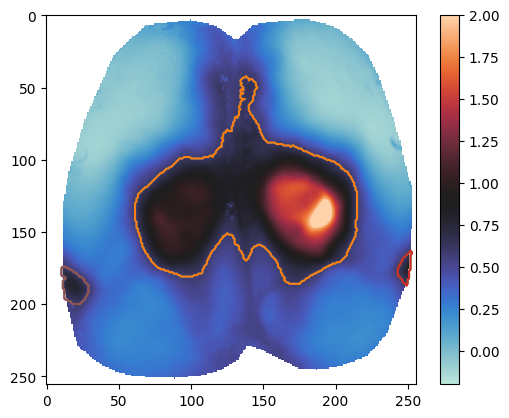

In [100]:
corr_map_here = corr_maps[:,:,100]
plt.imshow(corr_map_here,vmin=-0.2,vmax=2,cmap='icefire')
plt.colorbar()

from skimage import measure
filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_map_here>0.6)
contours = measure.find_contours(filled_bw, 0.1)

shape_of_contours = np.array([len(contour) for contour in contours])
keep_boolean = np.where(shape_of_contours>30)[0]
contours_copy = contours
contours = [contours_copy[i_ind] for i_ind in keep_boolean]

plt.imshow(corr_map_here,vmin=-0.2,vmax=2,cmap='icefire')


for i_c,contour in enumerate(contours):
    plt.plot(contour[:,1],contour[:,0])
    plt.plot(contour[:,1],contour[:,0])

In [66]:
from skimage import measure

In [106]:
new_IDX_safari_sorted.shape

(47,)

In [107]:
colors_jet.shape

(98, 4)

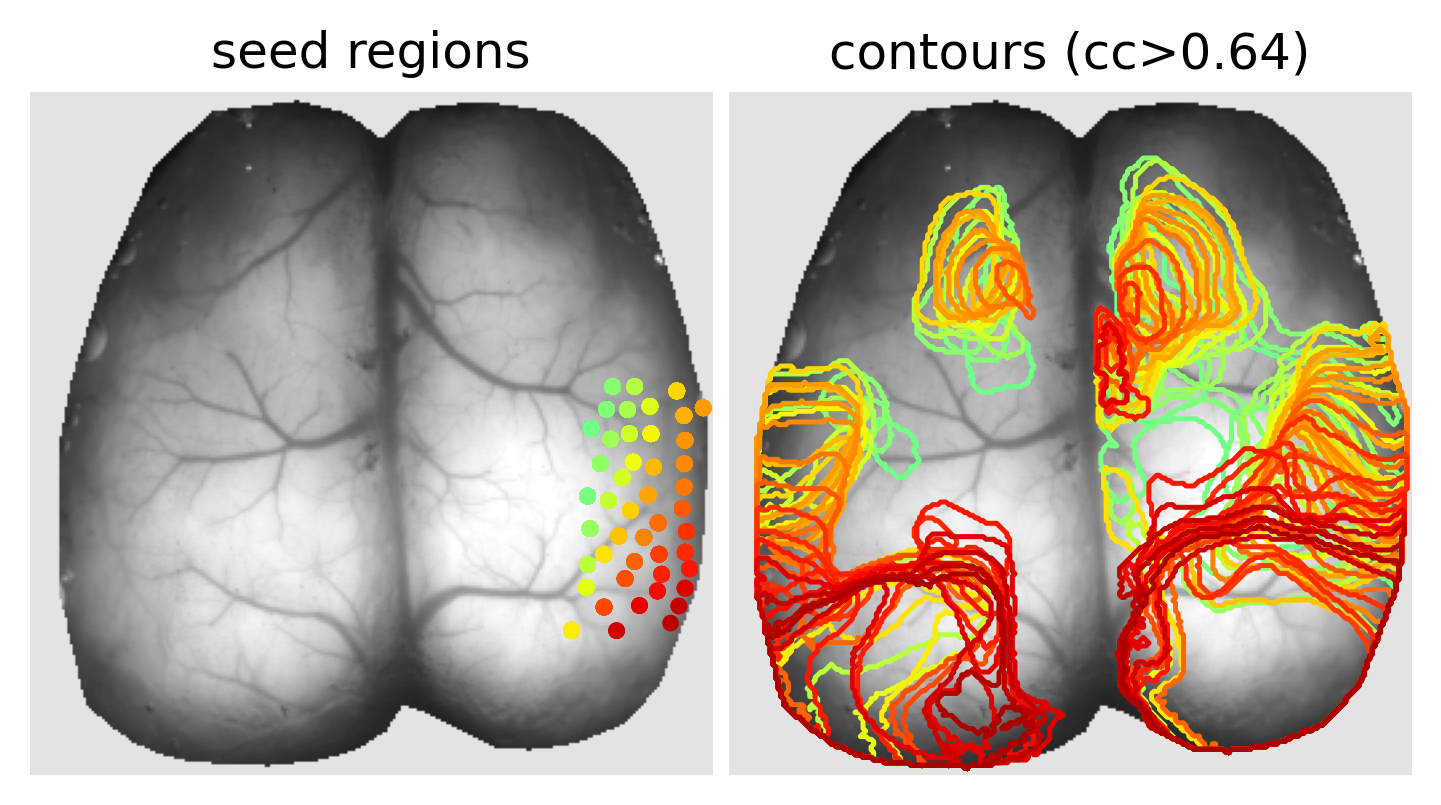

In [109]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])
ax0.axis('off')

x_start = x_stop
x_stop = x_start+x_width
ax1 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])
ax1.axis('off')

ax0.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)



ax1.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500)
for i_color,i in enumerate(range(len(new_IDX_safari_sorted))):
    ax0.scatter(node_coords[new_IDX_safari_sorted[:i],1],node_coords[new_IDX_safari_sorted[:i],0],s=9,color=colors_jet[n:n+i])

    corr_map_here = corr_maps[:,:,new_IDX_safari_sorted[i]]
    
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_map_here>0.64)
    contours = measure.find_contours(filled_bw, 0.1)
    
    shape_of_contours = np.array([len(contour) for contour in contours])
    keep_boolean = np.where(shape_of_contours>30)[0]
    contours_copy = contours
    contours = [contours_copy[i_ind] for i_ind in keep_boolean]
        
    for i_c,contour in enumerate(contours):
        ax1.plot(contour[:,1],contour[:,0],alpha=1,linewidth=1.2,color=colors_jet[n+i])

ax0.set_title('seed regions')
ax1.set_title('contours (cc>0.64)')

plt.savefig('figS4-continuous-M2-S1-v1.svg',format='svg',dpi=300)

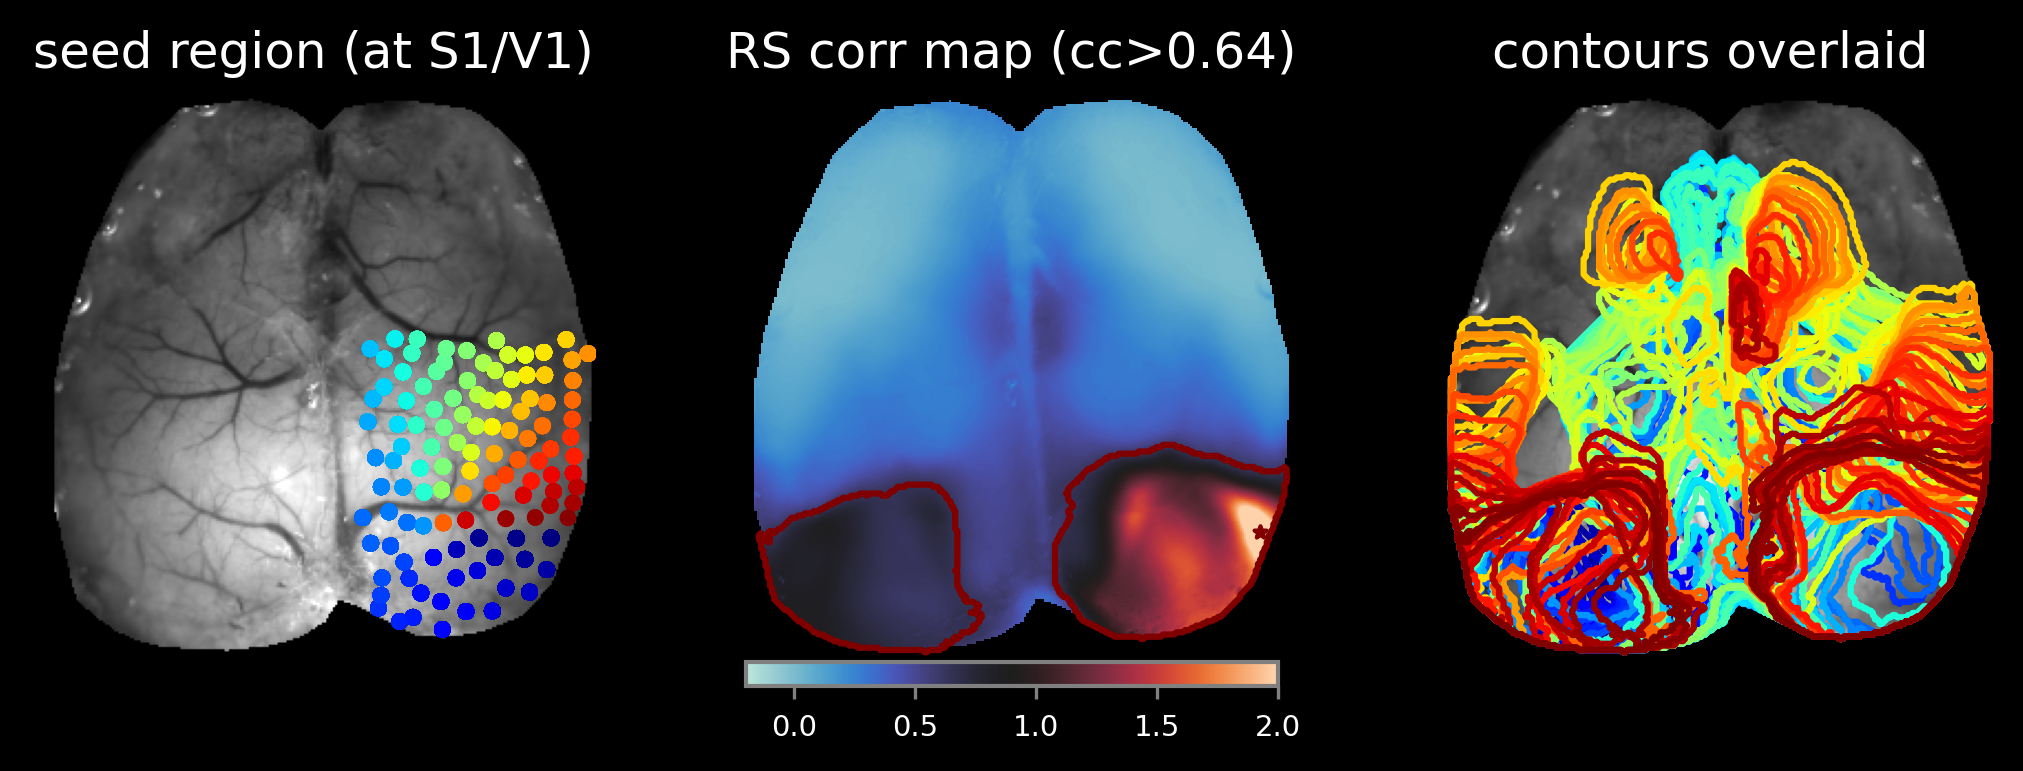

In [101]:
from matplotlib.gridspec import GridSpec
from matplotlib import ticker
plt.style.use('dark_background')
gs = GridSpec(28,90)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(9,2.8),dpi=300)
width = 25

ax1 = fig.add_subplot(gs[0:25,0:25]) 
ax2 = fig.add_subplot(gs[0:25,30:30+25]) 
ax3 = fig.add_subplot(gs[0:25,60:60+25]) 
ax99 = fig.add_subplot(gs[25:28,30+1:30+24]) 


###
ax1.imshow(np.multiply(mask,green[:,:,0]),cmap='gray',vmin=0,vmax=27000)
ax1.axis('off')
ax1.set_title('seed region (at S1/V1)')

ax3.imshow(np.multiply(mask,green[:,:,0]),cmap='gray',vmin=0,vmax=27000)
ax3.axis('off')
ax3.set_title('contours overlaid')


for i in range(len(IDX_safari_sorted)):
    ax1.scatter(node_coords[IDX_safari_sorted[:i],1],node_coords[IDX_safari_sorted[:i],0],s=9,color=colors[:i])
    corr_map_here = corr_maps[:,:,IDX_safari_sorted[i]]
    
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_map_here>0.64)
    contours = measure.find_contours(filled_bw, 0.1)
    
    shape_of_contours = np.array([len(contour) for contour in contours])
    keep_boolean = np.where(shape_of_contours>30)[0]
    contours_copy = contours
    contours = [contours_copy[i_ind] for i_ind in keep_boolean]
    
    # ax2 = fig.add_subplot(gs[0:25,30:30+25]) 
    ax2.cla()  
    ax2.set_title('RS corr map (cc>0.64)')
    sbp = ax2.imshow(corr_map_here,vmin=-0.2,vmax=2,cmap='icefire')
    ax2.scatter(node_coords[IDX_safari_sorted[i],1],node_coords[IDX_safari_sorted[i],0],s=9,marker='*',color=colors[i])
    ax2.axis('off')
    
    cb = fig.colorbar(sbp, cax=ax99,fraction=0.5,orientation='horizontal');
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=5)
    cb.locator = tick_locator
    cb.update_ticks()
    ax99.set_aspect(0.1)
    ax99.set_anchor('N')
    
    for i_c,contour in enumerate(contours):
        ax3.plot(contour[:,1],contour[:,0],color=colors[i])
        ax2.plot(contour[:,1],contour[:,0],color=colors[i])
        
    ax1.set_ylabel('mouse 1')
    plt.savefig('./cm125_save/'+str(i)+'.png',format='png',dpi=300)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in greater
  This is separate from the ipykernel package so we can avoid doing imports until


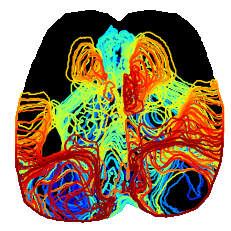

In [280]:
# plt.imshow(IDX_sorted,vmax=1,cmap='gray');plt.axis('off')
# for i in range(len(IDX_safari_sorted)):
#     filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_maps[:,:,IDX_safari_sorted[i]]**2>0.3)
#     contours = measure.find_contours(filled_bw, 0.1)
#     for i_c,contour in enumerate(contours):
#         plt.plot(contour[:,1],contour[:,0],color=colors[i])

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in greater
  import sys


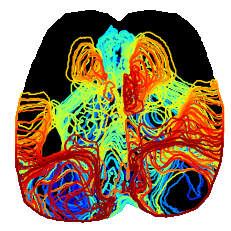

In [317]:
# ax = plt.subplot(111)
# ax.imshow(IDX_sorted,vmax=1,cmap='gray');plt.axis('off')


# for i in range(len(IDX_safari_sorted)):
# # for i in range(3):
#     filled_bw = scipy.ndimage.morphology.binary_fill_holes(corr_maps[:,:,IDX_safari_sorted[i]]**2>0.3)
#     contours = measure.find_contours(filled_bw, 0.1)
#     for i_c,contour in enumerate(contours):
#         plt.plot(contour[:,1],contour[:,0],color=colors[i])
#     plt.savefig('./save/'+str(i)+'.png',format='png',dpi=300)

In [102]:
a=[plt.imread('./cm125_save/'+str(n)+'.png') for n in range(len(IDX_safari_sorted))]

done w saving movie run


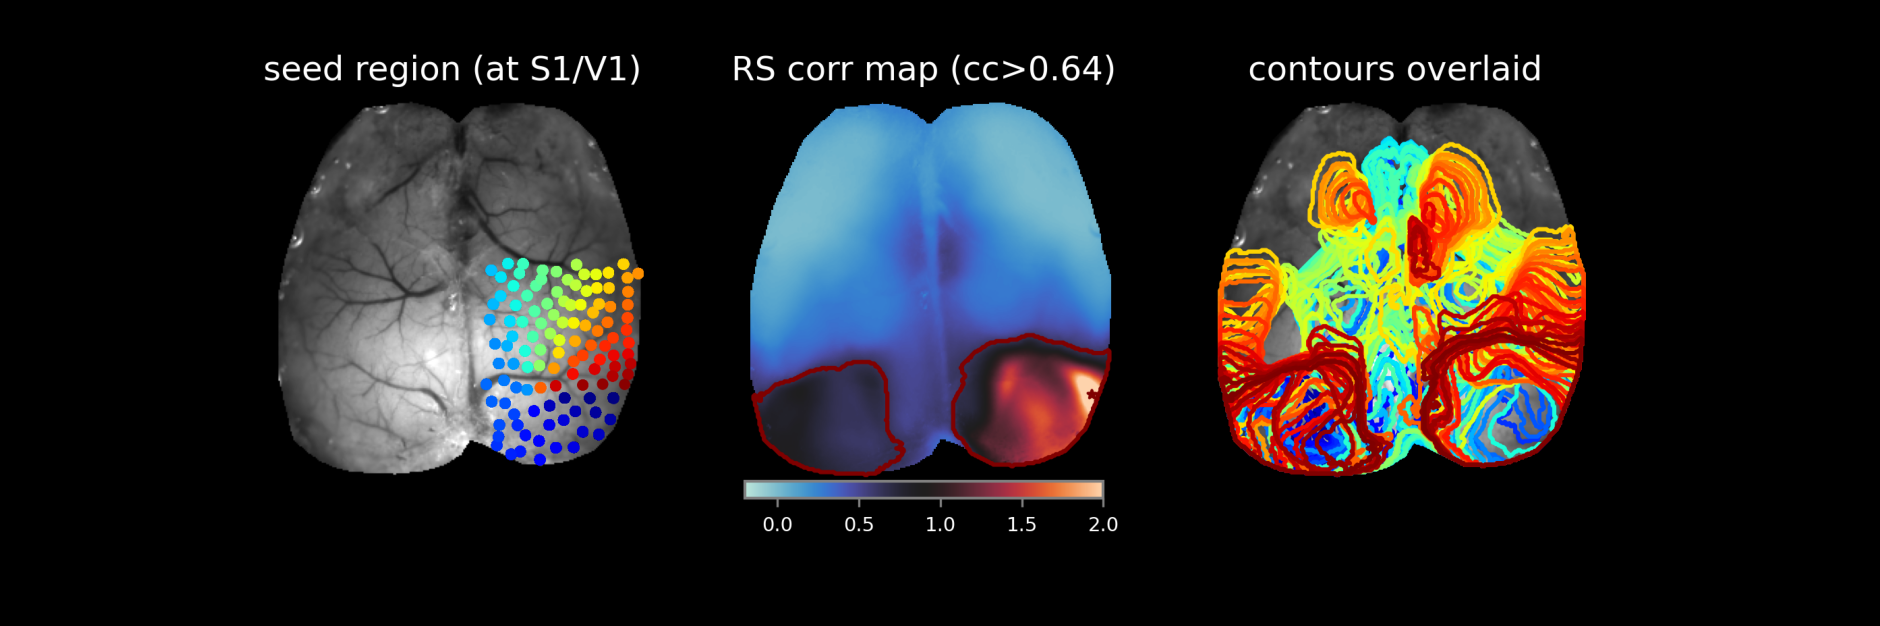

In [103]:

fig=plt.figure(figsize=(9,2.5),dpi=300)
ax = plt.subplot(111)
img = ax.imshow(a[0],vmax=1,cmap='gray');plt.axis('off')

def drawframe(n):
    
    img.set_array(a[n])
    
    return img,

anim = animation.FuncAnimation(fig, drawframe, frames=np.arange(0,len(IDX_safari_sorted)),
                               interval=50, blit=True)
anim.save('tryy-cm125.mp4', fps=5, extra_args=['-vcodec', 'libx264'])
print('done w saving movie run')


In [133]:
H=getH(M_jrgeco,IDX_sorted)

In [134]:
H.shape

(500, 41155)

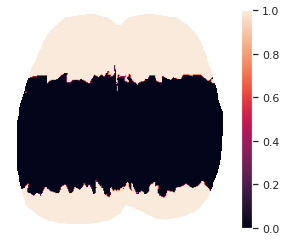

In [74]:
frontlines = np.logical_or(node_coords[:,0]<80,node_coords[:,0]>210)
show_map(frontlines,[0,1],IDX_sorted=IDX_sorted)

# NNLS

In [137]:
H_nnls = H[frontlines==True,:].transpose()

In [ ]:
from scipy.optimize import nnls
ss = M_jrgeco.shape
TCs_matrix = M_jrgeco.reshape((ss[0]*ss[1],ss[2]))
nanidx = ~np.isnan(TCs_matrix[:,0])
TCs_matrix = TCs_matrix[nanidx==True]
# for every region, fit TC to it
ncomps = H_nnls.shape[1]; M = np.empty((TCs_matrix.shape[0],ncomps))
for i_pixel in range(TCs_matrix.shape[0]):
    M[i_pixel,:],_ = nnls(H_nnls,TCs_matrix[i_pixel,:],2000)


In [141]:
all_path

'/scratch/users/wx2203/new_analysis_locker/pub-locker/heterogeneity/'

In [142]:
# save_pickle(M,all_path+mouse+'_nnls_M')

In [143]:
M.shape

(51714, 184)

In [163]:
H_nnls.shape

(41155, 184)

In [165]:
recon = np.dot(M,H_nnls.transpose())

In [166]:
recon.shape

(51714, 41155)

In [169]:
full_recon = np.zeros((ss[0]*ss[1],41155));full_recon[:]=np.nan
full_recon[nanidx==True]=recon

In [173]:
pan_mean = np.nanmean(full_recon,axis=1)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: Mean of empty slice
  """Entry point for launching an IPython kernel.


In [172]:
full_recon.shape

(65536, 41155)

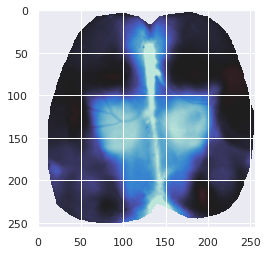

In [177]:
plt.imshow(pan_mean.reshape((256,256)),vmin=-0.01,vmax=0.01,cmap='icefire')

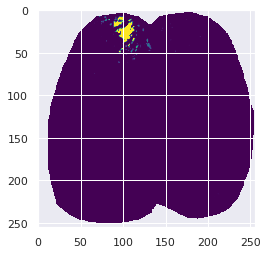

In [158]:
i_region=
full_spatial = np.zeros(ss[0]*ss[1]);full_spatial[:]=np.nan
full_spatial[nanidx==True]=M[:,i_region]
plt.figure()
full_spatial = full_spatial.reshape((ss[0],ss[1]))
plt.imshow(full_spatial,vmax=0.1,cmap='viridis')

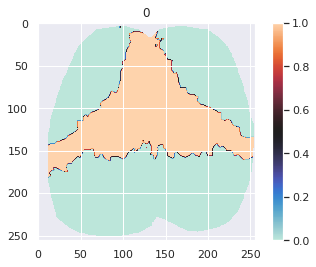

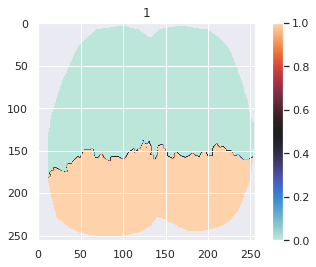

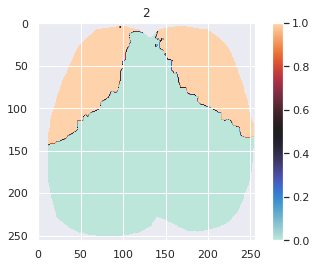

In [70]:
for i in range(3):
    plt.figure()
    a=kmeans.labels_==i
    show_map(a,caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)
    plt.axis('on')
    plt.title(i)

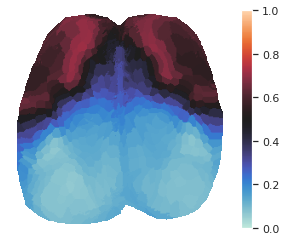

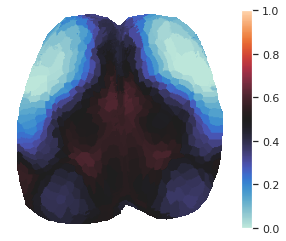

In [43]:

plt.figure()
show_map(kmeans.cluster_centers_[0,:],caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)
plt.figure()
show_map(kmeans.cluster_centers_[1,:],caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)
# plt.figure()
# show_map(kmeans.cluster_centers_[2,:],caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)
# plt.figure()
# show_map(kmeans.cluster_centers_[3,:],caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)
# plt.figure()
# show_map(kmeans.cluster_centers_[4,:],caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)

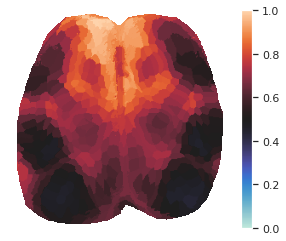

In [44]:
a=kmeans.cluster_centers_[0,:]+kmeans.cluster_centers_[1,:]
show_map(a,caxis=[0,1],cmap='icefire',IDX_sorted=IDX_sorted)

In [34]:
kmeans.cluster_centers_[0,:].shape

(500,)